# A growing building

How much room does the field have if the building is extended? This notebook scales every demand of
the office building of `demo_project.py` by up to 40 %, simulates each case over 25 years and plots
the coldest and the warmest entering fluid temperature against the temperature limits of the heat
pumps. It is the notebook version of `building_growth.py`.

Run it from the `examples` folder, with the executable and a licence (see
[Installation](../docs/install.md)).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import pyghe as ga
import ghestyle as ghe
from demo_project import make_project

ghe.use()

## One project per growth factor

The loads are series, not a single parameter, so I build the variants by hand and run them together
with `ga.run_many`.

In [2]:
growths = np.arange(1.0, 1.41, 0.05)                 # factor applied to every demand

p = make_project()
loads = p.building_loads
variants = []
for growth in growths:
    q = p.copy()
    q.building_loads = ga.HourlyBuildingLoadsSeparate(
        cooling_demand=loads.cooling_demand * growth,
        heating_demand=loads.heating_demand * growth,
        dhw_demand=loads.dhw_demand * growth)
    variants.append(q)

results = ga.run_many(variants, "simulate")
coldest = [r.summary.minimum_eft for r in results]
warmest = [r.summary.maximum_eft for r in results]
limit = p.heat_pump_performance.temperature_limit

for growth, low, high in zip(growths, coldest, warmest):
    print(f"loads x{growth:.2f}  ->  EFT from {low:5.2f} to {high:5.2f} °C")

loads x1.00  ->  EFT from  0.59 to 16.39 °C
loads x1.05  ->  EFT from  0.37 to 16.76 °C
loads x1.10  ->  EFT from  0.14 to 17.13 °C
loads x1.15  ->  EFT from -0.07 to 17.32 °C
loads x1.20  ->  EFT from -0.27 to 17.45 °C
loads x1.25  ->  EFT from -0.42 to 17.59 °C
loads x1.30  ->  EFT from -0.55 to 17.65 °C
loads x1.35  ->  EFT from -0.68 to 17.71 °C
loads x1.40  ->  EFT from -0.81 to 17.76 °C


## Figure

The dashed lines are the temperature limits. The coldest hour crosses the heating limit of 0 °C at
about 15 % of growth, while the warmest stays far from the cooling limit.

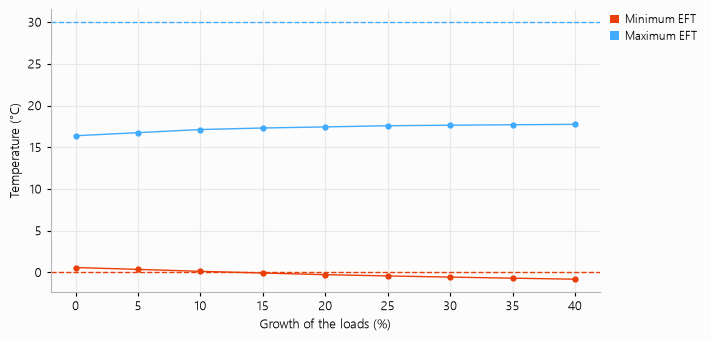

In [3]:
fig, ax = ghe.figure(width=7.0)
ax.plot(100 * (growths - 1), coldest, color=ghe.HEATING, marker="o", markersize=3.5)
ax.plot(100 * (growths - 1), warmest, color=ghe.COOLING, marker="o", markersize=3.5)
ax.axhline(limit.heating, color=ghe.HEATING, linestyle="--")
ax.axhline(limit.cooling, color=ghe.COOLING, linestyle="--")
ghe.legend(ax, [(ghe.HEATING, "Minimum EFT"), (ghe.COOLING, "Maximum EFT")])
ghe.axis_titles(ax, "Growth of the loads (%)", "Temperature (°C)")
plt.show()